# ABC for HPC
![](img/abchpc.png)
## Outline
- L1 - Introduction to HPC and SLURM (TODAY)
	- HPC terminology
	- Chimera
	- SLURM job submitting, monitoring, cancelling
	- MCP
- L2 - openMP, MPI (NEXT TIME)
- L3 - GPU, HPC Python (NEXT NEXT TIME)
- L4 - Profiling & optimalisation (NEXT NEXT NEXT TIME)

# High Performance Computing

### Moore's law
*"Every 18 months the power of CPU doubles."*

- $P \propto C*f*V^2$ hit the heat, size, density physics-based ceiling => multi-core

FLOP = Floating point operation

http://top500.org (green500)

HPC combines:
- fast hardware
- large number of inter-connected nodes (> 8000 servers)
- large memory (512 GB)
- high-speed networking (200 Gb/s)
- accelerators (GPU, TPU)
- huge storage (40TB)
- typically parallel algorithms
- login node(s)
- **scheduling**
- $\neq$ cloud (mostly a web-service)

![](img/hpc_building_blocks.png)

# Parallel Computing 
Parallel computation is like painting the room 4 walls or digging a water canal

![](img/parallel-dig.png)

### Flynn's taxonomy

|  |	Single instruction  |  Multiple instructions |
| :----------- |:--------------:| -------------:|
| Single data	 | SISD (old scalar CPU)  | MISD (rare, fault-tolerant systems)  | 
| Multiple data |	SIMD (vector units, GPUs) |	MIMD (multicore CPUs, clusters)     |



### Amdahl's law (fixed problem size)
If $f$ is the fully parallelisable fraction

serial part time $T_s = (1-f)T_1$

parallel part $T_p=fT_1/p$

=> $T = T_1 [ (1-f) + f/p ]$

 
Defining speed-up as $S(p)= T_1/T_p$

$$S(p) = \frac{1}{(1-f) + f/p}$$

$+$ overheads, initialisation, communication, I/O, memory transfers, synchronisation


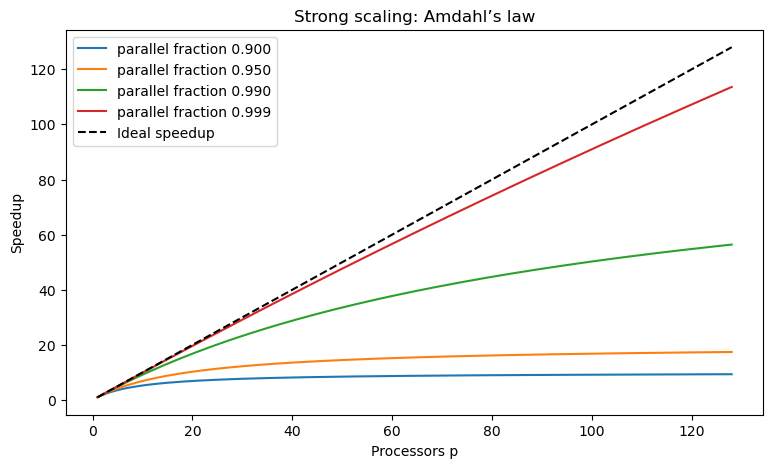

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display, Markdown

p = np.arange(1, 129)
fig, ax = plt.subplots(figsize=(9, 5))
for f in [0.90, 0.95, 0.99, 0.999]:
    ax.plot(p, 1 / ((1-f) + f/p), label=f'parallel fraction {f:.3f}')
ax.plot(p, p, 'k--', label='Ideal speedup')
ax.set(xlabel='Processors p', ylabel='Speedup', title='Strong scaling: Amdahl’s law')
ax.legend(); plt.show()

In [4]:
def amdahl(f=0.95, p=32):
    speedup = 1/((1-f)+f/p)
    print(f'f = {f:.2f}, {p} core: Speedup = {speedup:.2f}; efficiency = {speedup/p:.1%}; max speedup = {1/(1-f):.1f}')

f =0.90 # [ 0, 0.999]
p = 1000 # [1, 256]
amdahl(f, p)

f = 0.90, 1000 core: Speedup = 9.91; efficiency = 1.0%; max speedup = 10.0


- *strong* scaling -- the same amount of data faster 
- *weak* scaling -- bigger data in same amount of time


# Processes vs Threads

![](img/f1.png)

Process
* Independent address space
* Process ID (PID)
* Operating-system scheduling
* Process isolation

Thread
* Threads share the memory (address space) of their process.
* Each thread has its own execution state and stack.
* Threads can communicate through shared variables.
* Synchronization may be required.
* Pthreads standard
* Beware *race conditions*

![](img/processes-threads.png)

![](img/threads-dogs.png)

- **shared memory** -- threads (openMP)
- **distributed memory**, communication -- processes (MPI)
- **hybrid**, processes with treads -- (mixture of MPI w/openMP)

![](img/openmp-mpi-performance.png)

### Warning: Python has GIL (Global Interpreter Lock) - only 1 thread a time

However:

- C libraries (some numpy, scipy, tf, pytorch, pandas, BLAS, LAPACK...)
- JIT: numba, Cython

### NUMA (non-uniform memory access)
![](img/numa.png)

![](img/cpu-gpu2.png)

In [9]:
from numba import njit, prange, get_num_threads
from math import sin
from concurrent.futures import ThreadPoolExecutor
import time

@njit(nogil=True)
def calculate(start, end):
    result = 0.0
    for i in range(start, end):
        result += sin(i)
    return result

# warm up
calculate(0, 10)

N = 500_000_000

start = time.perf_counter()
result = calculate(0,N)
elapsed = time.perf_counter() - start
print(f"Serial elapsed time: {elapsed:.3f} s")
print("Serial:", result)

n_workers = 2 # try 4

starts = [i * N // n_workers for i in range(n_workers)]
ends = [(i + 1) * N // n_workers for i in range(n_workers)]

print("Threads:", get_num_threads())

start = time.perf_counter()
with ThreadPoolExecutor(max_workers=n_workers) as pool:
    results = list(pool.map(calculate, starts, ends))
result = sum(results)
elapsed = time.perf_counter() - start
print(f"Elapsed time: {elapsed:.3f} s")
print(result)

Serial elapsed time: 2.516 s
Serial: 1.934962807640717
Threads: 8
Elapsed time: 1.281 s
1.9349628076409364


In [10]:
from concurrent.futures import ProcessPoolExecutor

start = time.perf_counter()
with ProcessPoolExecutor(max_workers=n_workers) as pool:
    results = list(pool.map(calculate, starts, ends))
result = sum(results)
elapsed = time.perf_counter() - start

print(f"Elapsed time: {elapsed:.3f} s")
print(result)

Elapsed time: 1.920 s
1.9349628076409364


```bash
#!/bin/bash
#SBATCH --job-name=numba_threads
#SBATCH --partition=ffa
#SBATCH --ntasks=1
#SBATCH --cpus-per-task=4
#SBATCH --mem=2G
#SBATCH --time=00:05:00

# do not need srun to launch each worker: ProcessPoolExecutor creates the processes itself.
# ProcessPoolExecutor provides multiprocessing on a single node
python threads.py
```

### Multi-processing, mulit-threading - alternative

Each process has its own PID and memory space

```python
import multiprocessing as mp
import os

def worker(i):
    print(f"Worker {i}: PID = {os.getpid()}", flush=True)

if __name__ == "__main__":
    processes = []

    for i in range(4):
        p = mp.Process(target=worker, args=(i,))
        p.start()
        processes.append(p)

    for p in processes:
        p.join()
```

What happens?

* mp.Process() creates a process object.
* p.start() starts a new process.
* Each process executes worker(i) independently.
* p.join() waits until the process finishes.
* Each worker has a different PID.

The operating system can schedule these processes on different CPU cores.


All threads belong to the same process and share its memory

```python
import threading
import os

def worker(i):
    print(f"Worker {i}: PID = {os.getpid()}, Thread = {threading.current_thread().name}")

threads = []

for i in range(4):
    t = threading.Thread(target=worker, args=(i,))
    t.start()
    threads.append(t)

for t in threads:
    t.join()
```

What happens?

* threading.Thread() creates a thread object.
* t.start() starts a thread.
* Each thread executes worker(i).
* t.join() waits until the thread finishes.
* All threads have the same PID, but different thread identities.

Threads share memory, unlike independent processes.


# Chimera cluster
![](img/chimera-logo.png)

https://hpc.cuni.cz, https://hpc.cuni.cz/chimera/access/

- $>8838$ cores on 98 heterogeneous! computational nodes
- $>30$ GPU, ML
- SLURM scheduler

* Terminology: A cluster consists of nodes, which are grouped into partitions. Partitions may overlap.
* Users submit jobs (which may include multiple tasks - parallel processes) to a scheduling queue.

Admin contacts:
- Jiří Eliášek (utf))
- Ladislav Šubr (aauk)
- Michal Švanda (auuk)
- Zdeněk Mašín (utf, rse)
- myself (auuk, rse)

# Access to Chimera

```bash
ssh <CASlogin>@hpc.troja.mff.cuni.cz
```

```bash
ssh-keygen -t ed25519
# ssh-keygen -f ~/.ssh/id_ed25519_chimera -t ed25519
mkdir -p ~/.ssh
chmod 700 ~/.ssh
echo "PUBLIC_KEY" >> ~/.ssh/authorized_keys
chmod 600 ~/.ssh/authorized_keys
```
PUBLIC_KEY in ~/.ssh/id_ed25519.pub or 
```
ssh-copy-id -i <file> <where-to>
```

Optional ~/.ssh/config entry:
```bash
Host chimera
    HostName hpc.troja.mff.cuni.cz
    User YOUR_USERNAME
    IdentityFile ~/.ssh/id_ed25519
```


ReservationName=nast021_377, nast021

# JupyterHub

https://hpc.troja.mff.cuni.cz:8000/

## Parlab, Gpulab

![](img/chimera.png)

```bash
ssh -p 42222 <CASlogin>@parlab.ms.mff.cuni.cz
ssh -p 42222 <CASlogin>@gpulab.ms.mff.cuni.cz
```

Shutdown after use (just closing the browser is not enough)

## Local storage

- ```/home``` aka /troja/home 10 GB/user  - mirrored (backup)
- ```/work``` 100 TB, 40 TB/user
- ```/scratch``` - This is a fast network-attached storage shared across all nodes (ib) — for temporary large data
- ```/scratch_local```
- ```$TMPDIR``` RAM disk **Gone when job finishes, counted to the memory limit of the job!**

Chimera is using LUSTRE parallel file system. The ```/home``` storage is equipped with redundancy (mirroring) to guarantee continuous access and failure protection. NFS -> /troja/home

**Infiniband** 200Gb/s between *some* nodes

## File transfer, I/O
- ```scp```
- ```sftp``` (ls, put, get, mput, mget, lcd, pwd, lpwd, mkdir, rm, rmdir, quit, ...)
- ```sshfs```
- VScode Remote ssh extension
- github, gitlab
- ```rsync -avzP /path/to/file.iso <username>@hpc.troja.mff.cuni.cz:/path/to/directory/```
    - -a archive option used to preserve file timestamps and permissions
    - -v verbose option to monitor the transfer
    - -z compression option to compress the file during transfer
    - -p partial option to preserve partially transferred files in case of interruption

In [5]:
! du -h --max-depth=1 /work/$USER | sort -h

16K	/work/topim5am/jobarr
16K	/work/topim5am/mozaik_chimera
32K	/work/topim5am/requeue-test
40K	/work/topim5am/dmtcp_array_test
68K	/work/topim5am/MCP_logs
92K	/work/topim5am/no-requeue-test
156K	/work/topim5am/MCP_scripts
2.9M	/work/topim5am/mnist_tf
5.1M	/work/topim5am/nvidia-start
6.7M	/work/topim5am/training-materials
11M	/work/topim5am/requeue-test_home
15M	/work/topim5am/venvs
18M	/work/topim5am/infinity
20M	/work/topim5am/dmtcp_codex_test
64M	/work/topim5am/tf-test
68M	/work/topim5am/dmtcp
482M	/work/topim5am/containers
988M	/work/topim5am/rse
1.3G	/work/topim5am/scheckpoint-test
1.5G	/work/topim5am/git
4.4G	/work/topim5am


In [53]:
# quota -s

In [52]:
! lfs quota -h -u $USER /work

Disk quotas for usr topim5am (uid 65737654):
     Filesystem    used   quota   limit   grace   files   quota   limit   grace
          /work  4.375G     40T     50T       -   35904       0       0       -
uid 65737654 is using default block quota setting
uid 65737654 is using default file quota setting


In [8]:
%%bash
df -h ~
df -h /work
df -h /scratch

Filesystem                                                                 Size  Used Avail Use% Mounted on
10.76.232.8@o2ib:10.76.232.8@tcp2:10.76.232.7@o2ib:10.76.232.7@tcp2:/home   73T   30T   40T  44% /home
Filesystem                                                                 Size  Used Avail Use% Mounted on
10.76.232.8@o2ib:10.76.232.8@tcp2:10.76.232.7@o2ib:10.76.232.7@tcp2:/work  463T  381T   59T  87% /work
Filesystem                 Size  Used Avail Use% Mounted on
10.76.232.9@o2ib:/scratch  121T   98T   18T  85% /scratch


In [9]:
%%bash
# counts files in home
# find ~ -type f | wc -l

![](img/shared-distributed-mem.png)

# Modules

- Set of binaries, libraries, header files
- Loading a module modifies environment variables, PATH, LD_LIBRARY_PATH
- This enables executing module binaries and linking to module libraries

```module list | avail | spider | load | unload | purge```

```module spider GCC```

## On HPC clusters, scientific libraries are often installed through environment modules.

* FFTW — Fast Fourier Transform
* OpenBLAS — optimized linear algebra
* LAPACK — numerical linear algebra
* HDF5 — scientific data storage
* GSL — GNU Scientific Library
* MPI implementations
* NVIDIA stuff...

# Compiling
smaller on login, more resources-demanding  on node!

Makefile, ```make -j8```

## Warning: Chimera is heterogenous cluster
Optimize for the compilation host CPU. Be careful, Chimera is heterogenous. Choose nodes. Especially when compiling on the login node.

- Optimizations: -O0, -O1, -O2, -O3
- -march=native, -march=x86-64-v3
- -ffast-math (fast floating point, lower precision)
- -flto (link-time optimization)
- -fprofile-generate, -fprofile-use (enhance profiling)
- -fopenmp (enable OpenMP)
- -g (include debug symbols)   ???

Fortran, Intel ifx icx, intelMPI, MKL, gcc


hello.c:

```C
#include <stdio.h>

int main(void)
{
    printf("Hello HPC!\n");
    return 0;
}
```

```bash
gcc -O3 hello.c -o hello
```

Create a SLURM batch

```bash
#!/usr/bin/env bash
#SBATCH --job-name=simulation
#SBATCH --partition=edu
#SBATCH --nodes=1
#SBATCH --ntasks=1
#SBATCH --cpus-per-task=1
#SBATCH --time=00:05:00
#SBATCH --output=simulation_%j.out
./hello
```


```bash
# submit the slurm script 
sbatch run.slurm
```


### Intel compiler example

```bash
module spider intel
module load oneapi/intel_ipp_intel64/latest
icx hello.c -o hello
```


Add compilation on the running node
```bash
#!/usr/bin/env bash
#SBATCH --job-name=hello
#SBATCH --partition=edu
#SBATCH --nodes=1
#SBATCH --ntasks=1
#SBATCH --cpus-per-task=1
#SBATCH --time=00:05:00
#SBATCH --output=hello_%j.out

module load oneapi/intel_ipp_intel64/latest
icx hello.c -march=native -o hello
./hello
```

# Python

## venv (virtual environment)

```bash
python3 -m venv ~/myvenv
source ~/myvenv/bin/activate
(venv) pip install -U pip setuptools wheel
(venv) pip install numpy scipy matplotlib pandas
(venv) pip install <my_package> 
(venv) pip install numpy==1.26.4
deactivate
rm -rf ~/myvenv
```

Note: ```python -m pip install ...```

```
python -m pip list
python -m pip freeze > requirements.txt
python -m pip install -r requirements.txt
pip install -e . # developemt your own package

```

## Micromamba (Anaconda-like)

http://anaconda.org, http://mamba.readthedocs.io/en/latest/user_guide/micromamba.html

```"${SHELL}" <(curl -L micro.mamba.pm)```
```micromamba self-update```

```curl -Ls https://micro.mamba.pm/api/micromamba/$(uname)-$(uname -m)/latest | tar -xvj bin/micromamba```

```export MAMBA_ROOT_PREFIX=/some/prefix  # optional, defaults to ~/micromamba```
```eval "$(./bin/micromamba shell hook -s posix)"```

# SLURM

![](img/slurm.jpg)

SLURM manages resources and schedules jobs according to available resources
CPUs and memory, but it is able to manage other generic resources (GRES), like GPUs, etc. The time is resource as well.

A user is identified by his/her login. Account is a billing entity (MFF won't charge you for using the clusters). Each user must have assigned an account.

User can be assigned to more accounts and use them depending on what he/she is doing. Accounts can only be allowed access to certain partitions.


## Partitions (queues)

partition - a named group of compute nodes plus scheduling rules (the partitions may overlap):

    - maximum wall time
    - allowed users/accounts
    - priorities
    - available node types
    - etc.

By default, everyony has access to partitions
- *ffa* (free-for-all)
- *edu*


### Info about cluster state

```sview```, ```sinfo```, ```smypartition```, ```freenodes```

```sacctmgr show assoc user=$USER format=User,Account,Partition```

Preemption (jobs can be killed if higher priority arrives)

```squeue -s```
```squeue -u $USER # squeue --me```

# Submitting a job

1 Job -> n tasks -> m threads

- ```srun``` - reserves and assigns resources and runs an interactive job, use it only for short or debug jobs
- ```sbatch``` - reserves and assigns resources and submit a batch as a job, use it for long jobs (>1 hour)
- ```salloc``` - only reserves and does not assign resources, use srun or sbatch for assigning resources subsequently

Job submission commands (srun, sbatch, salloc) have a common set of important options:

| Short | Long | Description |
|-------|------|-------------|
| `-A` | `--account=` | Charge resources used by the job to the specified account. If not specified, the user's default account is charged. |
| `-B` | `--extra-node-info=` | Select nodes with at least the specified number of sockets, cores per socket, and threads per core. This is a constraint, not a resource allocation. |
| `-C` | `--constraint=` | Select only nodes with matching features. |
| `-c` | `--cpus-per-task=` | Number of CPUs allocated per task. |
| `-e` | `--error=` | Redirect standard error (stderr) to the specified file. |
| `-G` | `--gpus=` | Specify the number of GPUs required for the job, optionally including the GPU type. |
| | `--gres=` | Specify a comma-separated list of generic resources (GRES), in the form `name[[:type]:count]`. |
| `-i` | `--input=` | Redirect standard input (stdin) from the specified file. |
| `-J` | `--job-name=` | Specify the job name. |
| `-L` | `--licenses=` | Specify a comma-separated list of licenses required by the job, in the form `name[:count]`. |
| `-M` | `--clusters=` | Specify the clusters to issue commands to (comma-separated list or `all`). |
| | `--mem=` | Specify the memory required per node. Use `--mem=0` to request all available memory on each allocated node. |
| | `--mem-per-cpu=` | Specify the memory required per allocated CPU. |
| | `--mem-bind=` | Specify memory binding (NUMA memory placement). |
| `-N` | `--nodes=` | Specify the number of nodes to allocate. A single value requests that exact number; a range specifies minimum and maximum. Default is typically 1. |
| `-n` | `--ntasks=` | Specify the number of tasks. Default is typically 1. |
| `-o` | `--output=` | Redirect standard output (stdout) to the specified file. |
| `-p` | `--partition=` | Request a specific partition. If not specified, the default partition is used. |
| `-t` | `--time=` | Set the job time limit. Formats include `minutes`, `minutes:seconds`, `hours:minutes:seconds`, and `days-hours:minutes:seconds`. |
| | `--threads-per-core=` | Specify the maximum number of hardware threads per core. Setting `1` avoids using multiple hardware threads per core, similar to `--hint=nomultithread`. |
| `-a` | `--array=` | Specify job array indices. Each array element is a separate job with its own `SLURM_ARRAY_TASK_ID`. The shared array identifier is `SLURM_ARRAY_JOB_ID`. |


*Warning:* Don't forget to request GPU using --gpus=1, when running on gpu-xxx partitions


Does Slurm create the threads?

No! Slurm allocates CPU resources and runs tasks. It is the application that creates its own software threads and they run on allocated cores.


Once the job gets to the front of the queue

1. Slurm will allocate the specified number of nodes
2. The specified script will be executed
    • On the first allocated node
    • In submit directory
3. Once your script finishes, the job will also end
4. stdout and stderr of your script will be written to a file on the shared filesystem ```slurm-$JOB_ID.out```. They will be stored in the directory where you submit the job
    • You can override name with -o and -e

All bash variables are exported across the nodes

Useful environment variables available during a job

- SLURM_SUBMIT_DIR– directory from where you submitted the job
- SLURM_JOB_NODELIST – list of compute nodes
- SLURM_JOB_ID– job ID of the current job


```
echo "Running on host: $(hostname)"
echo "Job started at: $(date)"
echo "SLURM job ID: $SLURM_JOB_ID"
echo "Number of CPUs: $SLURM_CPUS_PER_TASK"
echo "$SLURM_JOB_PARTITION"
```


# Job handling

- ```scancel``` - cancels a job
- ```squeue``` - view info about scheduling queue
- ```sbcast``` - distributes a file to the nodes allocated to a job (obsolete on Chimera)
- ```sstat``` - display info about a job
- ```seff``` - displays statistics of resources for finnished job

```scancel <job-id>```

```scancel -u $USER -t PENDING```

# Useful examples

```srun --pty bash```
Stars interactive job (with bash as shell).
Interactive jobs do not work across clusters, please log into the correct frontnode to run interactive jobs.

```salloc```
Starts a shell in a minimal environment (resources). Useful for making small builds or debugging in a restricted environment.

Allocate resources:

```salloc -A PROJECT-ID -p qcpu -N 4 --ntasks-per-node 128 -t 2:00:00```

Start the job:

```srun–n 128 ./app```


```salloc -N2 -n4```
Starts a shell in a minimal environment with 4 tasks on 2 nodes from which you can run srun and see all outputs. Useful as an interactive debugging tool for MPI jobs.

```sbatch -p gpu-long --gpus=1 mygpucode.slurm```
Starts a batch job which will have one NVIDIA V100 card available.

```sinfo -o "%P %L %l"```
Prints info about default and maximum job time for partitions in a cluster.

```sinfo -o "%n %b %f"```
Prints info about current and available feature set for nodes in a cluster.

```sinfo -o "%.5P %.5a %.10l %.16F %.10p %N"```
Prints partition summary with priority.

```sinfo -Nel```
Prints nodes list with resources for every partition.

```srun -p mpi-homo-short -n 128 -N 8 --mem-per-cpu=2G mympijob```
Starts a MPI job with 128 tasks/ranks spanning over 8 nodes in the homogeneous partition assigning 1 CPU and 2 GB RAM to each task.

```
#!/bin/bash
#SBATCH --partition=ffa           # partition you want to run job in
#SBATCH --time=00:15:00           # walltime for the job in format (days-)hours:minutes:seconds
#SBATCH --mem=24000               # memory resource
#SBATCH --job-name="job_name"     # change to your job name
#SBATCH --output=output.txt       # stdout and stderr output file
#SBATCH --mail-user=user@example.com # send email when job changes state to email address user@example.com

# some real work here
```

# Hello hostname

job.slurm:

```bash
#!/usr/bin/env bash

#SBATCH --job-name=exercise2
#SBATCH --partition=edu
#SBATCH --nodes=1
#SBATCH --ntasks=4
#SBATCH --time=00:05:00

srun hostname
```

### sbatch header example

```bash
#!/bin/bash
#SBATCH --partition=ffa           # partition you want to run job in
#SBATCH --time=00:15:00           # walltime for the job in format (days-)hours:minutes:seconds
#SBATCH --nodes=2                 # number of nodes (can be only 1)
#SBATCH --ntasks-per-node=4       # processes per node
#SBATCH --mem=24000               # memory resource per node
#SBATCH --job-name="job_name"     # change to your job name
#SBATCH --output=output.txt       # stdout and stderr output file
#SBATCH --mail-user=user@example.com # send email when job changes state to email address user@example.com
#SBATCH --exclusive               # Use whole node
#SBATCH --signal SIGTERM@60       # send signal SIGTERM 60s before ending job (preemption, time limit)
```


### Table of symbols in sbatch

| Symbol	| Replaced with |
|---|---|
| %j	| Job ID (e.g. 123456) |
| %J	| Job ID plus step ID (e.g. 123456.0) |
| %x	 | Job name (from --job-name) |
| %u	 | Your username |
| %A	 | Main job ID of a job array |
| %a	 | Array task index (0, 1, 2, …) |
| %N	| Short hostname of the node (one file per node) |
| %n	 | Node index within the job (one file per node) |


```bash
#!/bin/bash
#SBATCH --job-name=myjob
#SBATCH --output=results.log
#SBATCH --error=errors.log
#SBATCH --open-mode=append
```

```bash
#!/usr/bin/env bash

#SBATCH --job-name=hello
#SBATCH --partition=edu
#SBATCH --nodes=2
#SBATCH --ntasks=4
#SBATCH --time=00:05:00
#SBATCH --output=hello_%j.out

echo "Job ID: $SLURM_JOB_ID"
echo "Allocated nodes: $SLURM_JOB_NODELIST"

srun hostname
```

# Running on other cluster
```
#!/bin/bash
#SBATCH --clusters parlab # on other sub-cluster
#SBATCH --partition ffa
#SBATCH --job-name test
#SBATCH --cpus-per-task 8
#SBATCH --mem-per-cpu 2g
#SBATCH --time 0:10:00

name=$(hostname)
echo "Hello from" $name
cat /troja/home/topim5am/git/clusters/README.md # be sure it is /troja/home, not /home
sleep 30s
```

```squeue -M parlab```

# Calculate Pi

calc_pi.py:
```python
import numpy as np
import sys

n_samples = int(sys.argv[1])
seed = int(sys.argv[2])
rng = np.random.default_rng(seed)

x = rng.random(n_samples)
y = rng.random(n_samples)
n_inside = np.count_nonzero(x*x + y*y <= 1)

print(4*n_inside/n_samples)
```

Simple serial

```bash
#!/bin/bash
#SBATCH --job-name=calc_pi
#SBATCH --partition=edu
#SBATCH --ntasks=1
#SBATCH --cpus-per-task=1
#SBATCH --mem=1G
#SBATCH --time=00:05:00
#SBATCH --output=pi_%j.out

python calc_pi.py 1000000 42
```

Harness multi-cores

```bash
#!/bin/bash

#SBATCH --job-name=calc_pi
#SBATCH --partition=edu
#SBATCH --nodes=2
#SBATCH --ntasks=8
#SBATCH --ntasks-per-node=4
#SBATCH --cpus-per-task=1
#SBATCH --mem=1G
#SBATCH --time=00:05:00
#SBATCH --output=pi_%j.out

# Run 8 independent calculations, each with a unique seed
srun bash -c 'python calc_pi.py 100000 "$SLURM_PROCID"'

# All tasks have finished. Calculate the average.
awk '/^[0-9]+\.[0-9]+$/ {sum += $1; n++}
     END {if (n > 0) printf "Average pi = %.10f (%d tasks)\n", sum/n, n}' \
    "pi_${SLURM_JOB_ID}.out"
```

# Job arrays

Submits multiple jobs XXXX_N.

The environment variable ```$SLURM_ARRAY_JOB_ID``` is set to the ID of the first job in the array
some real work here dependent on ```$SLURM_ARRAY_TASK_ID```

with job array

```bash
#!/bin/bash
#SBATCH --job-name=calc_pi
#SBATCH --partition=edu
#SBATCH --array=0-7
#SBATCH --ntasks=1
#SBATCH --cpus-per-task=1
#SBATCH --mem=1G
#SBATCH --time=00:05:00
#SBATCH --output=pi_%A_%a.out

python calc_pi.py 100000 "$SLURM_ARRAY_TASK_ID"
```

Collect the output

```bash
awk '{sum += $1; n++}
     END {printf "Average pi = %.10f (%d tasks)\n", sum/n, n}' \
    pi_*.out
```

Or have it in a script, too

collect_pi.sh:

```bash
#!/bin/bash
#SBATCH --job-name=collect_pi
#SBATCH --partition=edu
#SBATCH --ntasks=1
#SBATCH --time=00:01:00
#SBATCH --output=collect_%j.out

awk '{sum += $1; n++}
     END {printf "Average pi = %.10f (%d tasks)\n", sum/n, n}' \
    pi_${1}_*.out
```

```
JOBID=$(sbatch --parsable submit_pi.sh)
sbatch --dependency=afterok:$JOBID collect_pi.sh "$JOBID"
```

In [ ]:
```
# some real work here

#!/bin/bash
#SBATCH --partition=ffa           # partition you want to run job in
#SBATCH -A project                # use account project instead of default
#SBATCH --time=12:00:00         # walltime for the job in format (days-)hours:minutes:seconds
#SBATCH --nodes=1                 # number of nodes
#SBATCH --ntasks-per-node=1       # processes per node
#SBATCH --cpus-per-task=8         # cpus per tasks
#SBATCH --mem-per-cpu=2G          # memory resource per cpu
#SBATCH --array 0-127             # duplicate the job 128 times - slurm sets SLURM_ARRAY_TASK_ID environment variable which corresponds to the index each job in the array
#SBATCH -d afterok:10:12?after:13 # run this job after jobs with ID 10 and 12 ends successfully and job 13 starts executing (this line is optional and only an example of course)
#SBATCH --job-name="job_name"     # change to your job name
#SBATCH --error=error_%a.txt         # redirects stderr to error\_${SLURM_ARRAY_TASK_ID}.txt
#SBATCH --output=output_%a.txt       # redirects stdout to output\_${SLURM_ARRAY_TASK_ID}.txt
#SBATCH --mail-user=user@example.com # send email when job changes state to email address user@example.com
```

### scontrol show...

```bash
scontrol show job <job_ID>
scontrol show node <node_name> 
scontrol show partition ffa
scontrol show reservation
```

### Job Array helloworld

```bash
#!/bin/bash
##SBATCH --reservation nast021
##SBATCH --account nast021
#SBATCH --partition ffa
#SBATCH --job-name "test_job_array"
#SBATCH --cpus-per-task 1
#SBATCH --mem-per-cpu 100m
#SBATCH --time 0:10:00
#SBATCH --array 1-32%8 # duplicate the job 32 times - slurm sets SLURM_ARRAY_TASK_ID environment variable which corresponds to the index each job in the array
#SBATCH --error=error_%a.txt         # redirects stderr to error_${SLURM_ARRAY_TASK_ID}.txt
#SBATCH --output=output_%a.txt       # redirects stdout to output_${SLURM_ARRAY_TASK_ID}.txt

name=$(hostname)
echo "Hello from" $name "I am job " $SLURM_ARRAY_TASK_ID

sleep 300s
```

## Job array or for-loop?

submit_pi.slurm:

```#!/bin/bash
#SBATCH --job-name=calc_pi
#SBATCH --partition=edu
#SBATCH --ntasks=1
#SBATCH --cpus-per-task=1
#SBATCH --mem=1G
#SBATCH --time=00:05:00
#SBATCH --output=pi_result_%j.out

python pi.py 100000 "$1"
```


run_all.sh:

```bash
#!/bin/bash
for SEED in {0..3}; do
    sbatch submit_pi.sh "$SEED"
done
```

asssume all jobs finished...

```awk '{sum += $1; n++} END {printf "Average pi = %.10f (%d jobs)\n", sum/n, n}' pi_result_*.out```


### Interactive job

For debugging, profiling

```
srun --partition ffa --job-name "InteractiveJob" --cpus-per-task 8 --mem-per-cpu 2g --time 01:00:00 --pty bash
```


### Annotate the output
```srun --label hostname```

# Antoher example

Create configs:

```python
import json
configs = [
    {'scalar': 2.5, 'data': [1, 2, 3, 4, 5]},
    {'scalar': 3.0, 'data': [10, 20, 30]},
    {'scalar': -1.5, 'data': [2, -4, 8, 1]},
    {'scalar': 0.25, 'data': [12, 16, 20, 24]},
]
for i, cfg in enumerate(configs):
    ('configs'/f'config_{i}.json').write_text(json.dumps(cfg, indent=2)+'\n')
    print(f'config_{i}: {cfg} -> expected {cfg["scalar"] * sum(cfg["data"])}')
```

process_config.py:

```python
import argparse
import json
from pathlib import Path

def main():
    parser = argparse.ArgumentParser()
    parser.add_argument('config', type=Path)
    parser.add_argument('output', type=Path)
    args = parser.parse_args()
    cfg = json.loads(args.config.read_text())
    scalar, data = cfg['scalar'], cfg['data']
    result = scalar * sum(data)
    args.output.parent.mkdir(parents=True, exist_ok=True)
    args.output.write_text(f'{result:.17g}\n')
    print(f'{args.config} -> {args.output}: {result}')

if __name__ == '__main__':
    main()
```

### For-loop version

single_submit.slurm:

```bash
#!/usr/bin/env bash
#SBATCH --job-name=json_single
#SBATCH --ntasks=1
#SBATCH --cpus-per-task=1
#SBATCH --time=00:05:00
#SBATCH --output=logs/single_%j.out
set -euo pipefail
cd "$SLURM_SUBMIT_DIR"
python process_config.py "$1" "$2"
```


run_all.sh:

```bash
mkdir -p results

for i in {0..3}; do
    sbatch submit_config.sh \
        "configs/config_${i}.json" \
        "results/result_${i}.txt"
done
```

## Job Array version

```bash
#!/usr/bin/env bash
#SBATCH --job-name=json_array
#SBATCH --array=0-3%2
#SBATCH --ntasks=1
#SBATCH --cpus-per-task=1
#SBATCH --time=00:05:00
#SBATCH --output=logs/array_%A_%a.out
set -euo pipefail
cd "$SLURM_SUBMIT_DIR"
i="$SLURM_ARRAY_TASK_ID"
python src/process_config.py "configs/config_${i}.json" "results/array_result_${i}.txt"
```

### Job review
```sacct -u "$USER" --starttime today```


Display only jobs, without their individual steps

```sacct -u "$USER" --starttime today -X```

```sacct -u "$USER" --starttime today -X --format=JobID,JobName,State,Elapsed,AllocCPUS,MaxRSS,ExitCode```


From last 7 days:

``` sacct -u "$USER" --starttime "$(date -d '7 days ago' +%F)"```

Show completed jobs

```sacct -u "$USER" --starttime today --state=COMPLETED```

| Variable | Meaning |
|----|-----|
|SLURM_ARRAY_JOB_ID|Parent array job ID |
| SLURM_ARRAY_TASK_ID | Index of the array element|
|%A | Array job ID in output filenames|
|%a  |Array task index in output filenames  |

# Memory estimate

```
#SBATCH --nodes=1
#SBATCH --ntasks=1
#SBATCH --cpus-per-task=8
#SBATCH --mem=16G
#SBATCH --mem-per-cpu=4G
```


```python
import numpy as np
data = np.zeros((1000, 1000, 100), dtype=np.float64)
print(data.nbytes / 1024**3, "GiB")
```

```/usr/bin/time -v python myprogram.py

User time (seconds): 125.34
System time (seconds): 4.12
Percent of CPU this job got: 395%
Elapsed (wall clock) time: 0:32.81
Maximum resident set size (kbytes): 12582912
```

Rule of thumb: Peak performance * 1.3

```htop -d2```

 ```
sacct -j 123456 \ --format=JobID,JobName,State,Elapsed,ReqMem,MaxRSS,MaxVMSize
JobID       JobName     State      Elapsed    ReqMem   MaxRSS
123456      analysis    COMPLETED  00:15:23   32G
123456.batch batch      COMPLETED  00:15:23            12G
```



```python
import os
import psutil
import numpy as np
process = psutil.Process(os.getpid())
def memory_usage():
    rss = process.memory_info().rss
    return rss / 1024**3
print(f"Initial memory: {memory_usage():.3f} GiB")
a = np.ones((10000, 10000), dtype=np.float64)
print(f"After allocation: {memory_usage():.3f} GiB")
b = a.copy()
print(f"After copying: {memory_usage():.3f} GiB")
```


```sinfo -N -o "%N %c %m %e"```

%N Node name, %c Number of CPUs, %m Configured real memory (MB), %e Free memory reported by Slurm (MB)

```scontrol show node <node_name>```

```free -h```


# Checkpointing

```bash
#!/bin/bash
#SBATCH --job-name=simulation
#SBATCH --partition=ffa
#SBATCH --time=02:00:00
#SBATCH --signal=B:USR1@120

module load DMTCP

source /usr/local/bin/scheckpoint \
    --tiger-jump \
    --tiger-jump-size 00:05:00 \
    python simulation.py
```

```--tiger-jump```, if used, the simulation is started on the 'checkpoint' partition on an old hardware to ensure instruction compatibility with the rest of the nodes. It is useful for some compiled binaries. scheckpoint uses DMTCP under the hood. Note the use of source, to ensure it does not create a new process and therefore can listen to SLURM signals

### Warning: Does not work for multi-nodes apps, such as MPI
### Warning: Does not work with GPU


# Containers
apptainer (singularity), podman (Docker)

Good container (video) tutorial on www.archer2.ac.uk/training/courses/220119-containers/


# MCP (Model Context Protocol)

Harness LLM (codex, claude code, ...)

https://www.hpc.cuni.cz/chimera/ai-llm/

![](img/burj-cz.png)

# Core bindings


Node with 2 CPU sockets, 16 physical cores, each of 2 HW cores (SMT, also called Hyper-Threading on Intel) = 64 logical CPUs in total where OS can schedule work onto. Linux schedules individual threads, not just processes to balance workload.

Too much migration reduces performance, as data not in cache.

Thread affinity = at which CPUs a thread can run


```lscpu```

```lscpu -e=CPU,CORE,SOCKET,NODE,ONLINE```


```taskset -pc $$```, taskset -c 2,3 python simulation.py


```taskset -pc 2,3 <PID>```


```grep Cpus_allowed_list /proc/self/status```

```cat /proc/12345/task/12346/status```

avoid over-subscription

SLURM uses cgroups = control groups to enforce job allocation

CPU allocation
memory consumtion
CPU placement
I/O resources
Process counts


srun --cpu-bind=cores python sim.py

#SBATCH --ntasks=4
#SBATCH --cpus-per-task=4
srun python sim.py
4x4=16 workers


--hint=compute_bound

Prefer using all cores within fewer sockets

--hint=memory_bound

Prefer spreading tasks across sockets, typically one core per socket

--hint=multithread

Permit use of multiple hardware threads per physical core

--hint=nomultithread

Prefer one hardware thread per physical core

| Option | Meaning | Typical use |
| --- | --- | --- |
| --cpu-bind=none | Do not explicitly bind tasks | Let OS scheduler decide |
| --cpu-bind=threads |  Bind tasks at logical CPU (hardware-thread) granularity | Fine-grained CPU placement
| --cpu-bind=cores | Bind tasks to physical cores, potentially including their SMT siblings | General HPC workloads |
| --cpu-bind=sockets | Bind tasks to CPU sockets | NUMA-aware workloads |
| --cpu-bind=ldoms | Bind tasks to NUMA locality domains | Memory-intensive workloads |
| --cpu-bind=rank | Bind tasks according to task rank | Explicit task placement |
| --cpu-bind=map_cpu:<list> | Explicit logical CPU mapping |  Advanced affinity control |
| --cpu-bind=mask_cpu:<list> |   Explicit CPU affinity masks | Advanced affinity control |
| --cpu-bind=verbose |  Print CPU-binding information | Debugging |